<div align="center">

# CCT College Dublin Continuous Assessment

</div>

---

| Field | Details |
| :--- | :--- |
| **Programme Title:** | BSc Computing and IT |
| **Delivery Mode:** | FT |
| **Cohort Details:** | DataVisComms_BScCompIT_Sept23 FT Stage 4 Semester 1 |
| **Module Title(s):** | Data Visualisation and Communication |
| **Assignment Type:** | Individual (60%) |
| **Assignment Title:** | CA2 |
| **Lecturer(s):** | Taufique Ahmed |
| **Student Name:** | Selim Boujneh |
| **Student ID:** | 2023431 |
| **Issue Date:** | 09-11-2026 |
| **Submission Deadline Date:** | 04-12-2026, 23:59 |
| **Late Submission Penalty:** | Late submissions will be accepted up to **5** calendar days after the deadline. All late submissions are subject to a penalty of **10% of the mark awarded**. Submissions received more than 5 calendar days after the deadline above **will not** be accepted and a mark of 0% will be awarded. |
| **Method of Submission:** | This assignment is submitted via Moodle. |
| **Instructions for Submission:** | Submit a Jupyter Notebook (`.ipynb`) to Moodle. Do **NOT** upload any data.<br>Record a 5-minute screen capture explaining your work. Save the video to your Google Drive, set the sharing permissions to “Anyone with the link,” and then upload the link to Moodle.<br>Add GitHub and recorded video link in the first cell of the Jupyter notebook.<br>Word document, which covers the use of AI. |
| **GitHub Classroom Link:** | Create your own GitHub repository and provide access to `tahmed1986` GitHub account. |
| **Feedback Method:** | Results posted in Moodle gradebook |
| **Feedback Date:** | TBD |

---

# Data Visualisation and Communication (CA2)
# Student Name: Selim boujneh  
# Student ID: 2023431  
# Module: Data Visualisation and Communication  
# Lecturer: Taufique Ahmed
# GitHub Repository link: 
# Presentation link: 


In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## 1. Data Assessment, Cleaning and Preparation

I started by inspecting the Online Retail workbook to understand its structure and date coverage. then I checked for missing values, duplicate rows, cancelled transactions, non-positive quantities and prices, and unusually large values. These checks guide which records I keep or exclude and how I prepared the data for sales analysis.

Each row represents one line item. I calculated the sales value for each line and aggregated the relevant lines by invoice to calculate order values.

### 1.1 Load and Inspect the Workbook

In [2]:
# Dataset loadding and exploration
df= pd.read_excel('Online Retail.xlsx')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Dataset shape:", df.shape)
df.info()

print("First invoice:", df["InvoiceDate"].min())
print("Last invoice:", df["InvoiceDate"].max())

df[["Quantity", "UnitPrice"]].describe()


Dataset shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
First invoice: 2010-12-01 08:26:00
Last invoice: 2011-12-09 12:50:00


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


I summarised Quantity and UnitPrice because multiplying them gives the value of each invoice line. Both columns contained negative values, so I checked their frequency and whether they were linked to cancellations. InvoiceDate loaded as a datetime, so I could use it directly to check the period covered.

### 1.2 Data Quality Audit

I checked for missing values, exact duplicates, cancellation codes and
non-positive quantities or prices. Some of these checks can flag the same
row, so I also counted how many rows meet at least one of the three conditions.

In [5]:
print("Missing values by column:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values by column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate rows: 5268


In [6]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
non_positive_quantity = df["Quantity"] <= 0
non_positive_price = df["UnitPrice"] <= 0

flagged_transactions = cancelled | non_positive_quantity | non_positive_price

print("Lines with a cancellation code:", cancelled.sum())
print("Lines with non-positive quantity:", non_positive_quantity.sum())
print("Lines with non-positive unit price:", non_positive_price.sum())
print("Lines meeting at least one rule:", flagged_transactions.sum())

Lines with a cancellation code: 9288
Lines with non-positive quantity: 10624
Lines with non-positive unit price: 2517
Lines meeting at least one rule: 11805


In [7]:
sales_for_review = df[~flagged_transactions]

for column in ["Quantity", "UnitPrice"]:
    q1 = sales_for_review[column].quantile(0.25)
    q3 = sales_for_review[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = sales_for_review[
        (sales_for_review[column] < lower) |
        (sales_for_review[column] > upper)
    ]

    print(f"{column}: bounds {lower:.2f} to {upper:.2f}")
    print(f"Flagged lines: {len(outliers):,}")
    display(outliers.sort_values(by=column, ascending=False).head())

Quantity: bounds -12.50 to 23.50
Flagged lines: 56,363


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82,18087.0,United Kingdom


UnitPrice: bounds -3.07 to 8.45
Flagged lines: 37,999


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029.0,United Kingdom
297723,562955,DOT,DOTCOM POSTAGE,1,2011-08-11 10:14:00,4505.17,NaN,United Kingdom
268028,560373,M,Manual,1,2011-07-18 12:30:00,4287.63,NaN,United Kingdom


In [8]:
largest_quantity_lines = df[df["Quantity"].isin([80995, -80995, 74215, -74215])]

largest_quantity_lines[
    ["InvoiceNo", "InvoiceDate", "StockCode", "Description",
     "CustomerID", "Quantity", "UnitPrice"]
].sort_values(by=["StockCode", "InvoiceDate"])

,InvoiceNo,InvoiceDate,StockCode,Description,CustomerID,Quantity,UnitPrice
61619,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,12346.0,74215,1.04
61624,C541433,2011-01-18 10:17:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,12346.0,-74215,1.04
540421,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",16446.0,80995,2.08
540422,C581484,2011-12-09 09:27:00,23843,"PAPER CRAFT , LITTLE BIRDIE",16446.0,-80995,2.08


I used the IQR method to flag unusual quantities and unit prices for review (outliers). A large value alone was insufficient reason to remove a sale because it could represent a bulk purchase or a higher-priced item. For the two largest quantities, I found a later cancellation for the same customer and product, at the same unit price and with the opposite quantity. I kept the purchases when calculating the original order values and included the credits when calculating net sales.

## 1.3 Data Cleaning
**Handling Duplicates**

In [9]:
clean_df = df.copy()
clean_df.drop_duplicates(keep="first", inplace=True)

print("Invoice lines remaining:", len(clean_df))
print("Duplicates remaining:", clean_df.duplicated().sum())

Invoice lines remaining: 536641
Duplicates remaining: 0


I treated rows that matched across all eight columns as duplicates and retained the first occurrence. Because the dataset has no unique invoice-line ID, this may undercount genuine repeated entries for the same product on the same invoice.

**Handling Cancellations and Non-positive Values**

In [10]:
cancelled = clean_df["InvoiceNo"].astype(str).str.startswith("C")
non_positive_quantity = clean_df["Quantity"] <= 0
non_positive_price = clean_df["UnitPrice"] <= 0

flagged_transactions = cancelled | non_positive_quantity | non_positive_price

print("Lines with a cancellation code:", cancelled.sum())
print("Lines with non-positive quantity:", non_positive_quantity.sum())
print("Lines with non-positive unit price:", non_positive_price.sum())
print("Lines meeting at least one rule:", flagged_transactions.sum())

Lines with a cancellation code: 9251
Lines with non-positive quantity: 10587
Lines with non-positive unit price: 2512
Lines meeting at least one rule: 11763


In [11]:
# Positive purchase lines for order counts and original order values
sales_df = clean_df[
    (cancelled == False) &
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

# Cancellation credits that reduce sales value
cancellation_credits = (
    cancelled &
    (clean_df["Quantity"] < 0) &
    (clean_df["UnitPrice"] > 0)
)

# Keep both purchases and cancellation credits for net sales value
net_sales_df = clean_df[
    ((cancelled == False) &
     (clean_df["Quantity"] > 0) &
     (clean_df["UnitPrice"] > 0)) |
    cancellation_credits
].copy()

print("Positive purchase lines:", len(sales_df))
print("Cancellation credit lines held:", cancellation_credits.sum())
print("Lines for net sales analysis:", len(net_sales_df))

Positive purchase lines: 524878
Cancellation credit lines held: 9251
Lines for net sales analysis: 534129


**Missing values (Customer IDs and Product Descriptions)**

In [12]:
print("Missing values in purchase lines:")
print(sales_df[["CustomerID", "Description"]].isnull().sum())

print("Missing values in net sales lines:")
print(net_sales_df[["CustomerID", "Description"]].isnull().sum())

# Keeping identified customers for customer-level purchase analysis
customer_sales_df = sales_df.dropna(subset=["CustomerID"]).copy()

print("Purchase lines with a customer ID:", len(customer_sales_df))
print("Purchase lines excluded from customer analysis:",
      len(sales_df) - len(customer_sales_df))

Missing values in purchase lines:
CustomerID     132186
Description         0
dtype: int64
Missing values in net sales lines:
CustomerID     132565
Description         0
dtype: int64
Purchase lines with a customer ID: 392692
Purchase lines excluded from customer analysis: 132186


I retained lines with missing customer IDs in the overall sales analysis because their values still contribute to totals by date and country. For customer-level purchase analysis, I used only lines with a recorded customer ID. After filtering the transactions, I found zero missing product descriptions in both the purchase data and the net sales data.

**Calculating line values and order totals**

In [13]:
# Calculate the value of each invoice line
sales_df["LineValue"] = sales_df["Quantity"] * sales_df["UnitPrice"]
net_sales_df["LineValue"] = net_sales_df["Quantity"] * net_sales_df["UnitPrice"]

# Add the purchase lines on each original invoice (The total foe same invoice)
order_values = sales_df.groupby("InvoiceNo")["LineValue"].sum()

print("Original orders:", len(order_values))
print(f"Original purchase value: £{order_values.sum():,.2f}")
print(f"Net sales after recorded credits: £{net_sales_df['LineValue'].sum():,.2f}")

order_values.head()

Original orders: 19960
Original purchase value: £10,642,110.80
Net sales after recorded credits: £9,748,131.07


InvoiceNo
536365    139.12
536366     22.20
536367    278.73
536368     70.05
536369     17.85
Name: LineValue, dtype: float64

### 1.4 Data Validation and Limitations

In [14]:
purchase_total = sales_df["LineValue"].sum()
invoice_total = order_values.sum()

credit_lines = net_sales_df[net_sales_df["Quantity"] < 0]
credit_total = credit_lines["LineValue"].sum()
net_total = net_sales_df["LineValue"].sum()

print(f"Difference after grouping by invoice: £{invoice_total - purchase_total:,.2f}")
print(f"Recorded cancellation credits: £{credit_total:,.2f}")
print(f"Difference after accounting for credits: £{net_total - (purchase_total + credit_total):,.2f}")

Difference after grouping by invoice: £0.00
Recorded cancellation credits: £-893,979.73
Difference after accounting for credits: £0.00


Grouping purchase lines by invoice preserves the original purchase value (£10,642,110.80). Recorded cancellations worth £893,979.73 in credits bring net sales to £9,748,131.07. Note that customer-level metrics include only transactions with a recorded customer ID, and December 2011 reflects a partial month ending on 9 December 2011.

**Cleaning decisions and their impact on the analysis**

- I prepared the data to answer two management questions: how much customers originally ordered and how much sales value remained after recorded credits.
- I grouped positive purchase lines by invoice to calculate the original values of 19,960 orders. For net sales, I included cancellation credits at their negative values. I confirmed that the total value of the 19,960 orders was £10,642,110.80, which matched the sum of all purchase lines. After subtracting £893,979.73 in recorded cancellation credits, the remaining value was £9,748,131.07, consistent with my net sales calculation.

These decisions guide the charts in Task 2. Order-value charts will use one total per purchase invoice, while sales trends will include recorded credits. Customer-level findings cover only purchases with a recorded customer ID. December 2011 ends on 9 December, so I will label it as a partial month.

## 2. Exploratory Data Analysis (EDA) and Static Visualisations

I used the cleaned transaction data to explore how sales changed over time, which products and countries contributed most to net sales, and how order values and purchasing patterns varied across customers.

### 2.1 Monthly Net Sales

I calculated monthly net sales by adding the purchase and cancellation values recorded in each month. I chose a line chart because it shows how sales changed from one month to the next and makes peaks and declines easy to identify.

In [16]:
# Use the invoice date to group transaction values by month
sales_by_date = net_sales_df.set_index("InvoiceDate")
monthly_sales = sales_by_date["LineValue"].resample("MS").sum()

print(monthly_sales.round(2))
print(f"Total net sales: £{monthly_sales.sum():,.2f}")

InvoiceDate
2010-12-01     746723.61
2011-01-01     558448.56
2011-02-01     497026.41
2011-03-01     682013.98
2011-04-01     492367.84
2011-05-01     722094.10
2011-06-01     689977.23
2011-07-01     680156.99
2011-08-01     703510.58
2011-09-01    1017596.68
2011-10-01    1069368.23
2011-11-01    1456145.80
2011-12-01     432701.06
Freq: MS, Name: LineValue, dtype: float64
Total net sales: £9,748,131.07


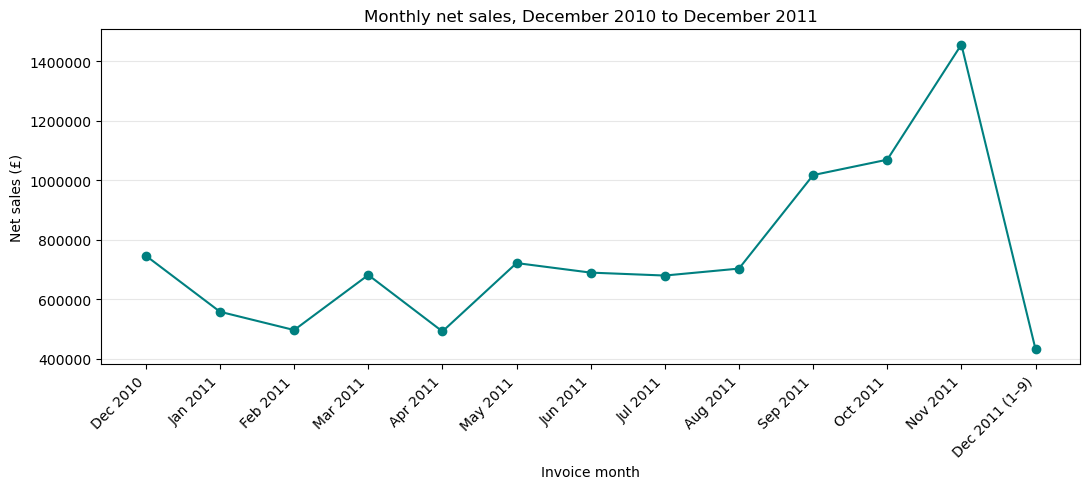

In [18]:
month_labels = monthly_sales.index.strftime("%b %Y").tolist()
month_labels[-1] = "Dec 2011 (1–9)"

plt.figure(figsize=(11, 5))
plt.plot(month_labels, monthly_sales.values, marker="o", color="teal")

plt.title("Monthly net sales, December 2010 to December 2011")
plt.xlabel("Invoice month")
plt.ylabel("Net sales (£)")
plt.xticks(rotation=45, ha="right")
plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Monthly net sales exceeded £1 million for three consecutive months from September to November 2011. November was the strongest month, with net sales of £1.46 million, a 36.2% increase from October. The final point covers only the first nine days of December, so the apparent drop cannot establish whether sales declined over the full month.